# Задача 4.13
# Добавление белого шара при случайном составе корзины

## Условие
В корзине $n$ шаров. Начальное число белых $K$ имеет биномиальное распределение с параметрами $n,p$. Добавляют один белый шар и наудачу извлекают один из $n+1$. Найти вероятность белого в общем случае и при $n=10,p=1/3$.

## Теория с нуля и решение вручную
### 1. Биномиальное распределение
Если каждый из $n$ шаров независимо белый с вероятностью $p$, число белых $K$ имеет закон
$$P(K=k)=\binom nkp^k(1-p)^{n-k},\qquad k=0,\ldots,n.$$
Коэффициент выбирает, какие именно $k$ шаров белые. Биномиальное распределение описывает случайный **состав** корзины до извлечения. Число всех шаров $n$ фиксировано.

### 2. Полная вероятность
При известном составе $K=k$ после добавления белых $k+1$, всего $n+1$:
$$P(A\mid K=k)=\frac{k+1}{n+1}.$$
Гипотезы $K=0,1,\ldots,n$ несовместны и исчерпывают возможности. Формула полной вероятности усредняет условные вероятности:
$$P(A)=\sum_{k=0}^n\frac{k+1}{n+1}\binom nkp^k(1-p)^{n-k}.$$

### 3. Математическое ожидание сокращает сумму
Математическое ожидание дискретной величины — взвешенное среднее $E[K]=\sum kP(K=k)$. Можно представить $K=I_1+\cdots+I_n$, где индикатор белизны $I_i$ имеет ожидание $p$. По линейности $E[K]=np$:
$$P(A)=\frac{E[K]+1}{n+1}=\frac{np+1}{n+1}.$$
Ещё одно объяснение: с вероятностью $1/(n+1)$ выбран добавленный белый шар, с вероятностью $n/(n+1)$ выбран один из исходных, белый с вероятностью $p$.
При заданных числах
$$P(A)=\frac{10/3+1}{11}=\frac{13}{33}\approx0.39393939.$$
Ответ $0.15625$ в листке не соответствует этому условию. Проверка: добавление гарантированно белого шара должно повысить вероятность относительно $p=1/3$, а $0.15625<1/3$. Формула даёт $p+(1-p)/(n+1)$, что явно не меньше $p$.

### 4. Переход к коду
`rng.binomial(n,p,N)` моделирует число успехов в $n$ независимых испытаниях Бернулли; здесь успех означает белый исходный шар. Затем выбираем целый номер из $n+1$ шаров. Считаем первыми $K+1$ номеров белые. В коде также вычисляем полную сумму точными дробями и проверяем её равенство короткой формуле.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

Полная сумма: 13/33 ; короткая формула: 13/33
После добавления извлечён белый шар: успехов 59269, знаменатель 150000
  частота = 0.39512667; ориентир 95%: [0.39265260; 0.39760073]
  теория = 0.39393939; разность = +0.00118727


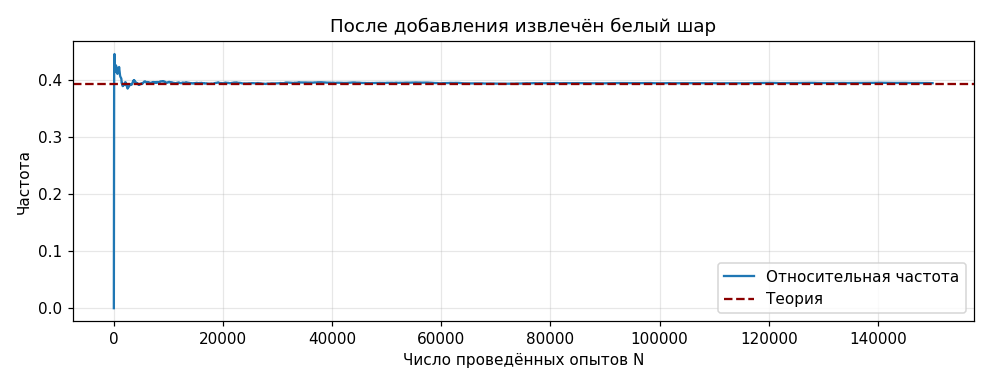

In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

N = 150_000
n = 10
p_exact = Fraction(1,3)
exact = (n*p_exact+1)/(n+1)
full_sum = sum(Fraction(k+1, n+1)*math.comb(n,k)*p_exact**k*(1-p_exact)**(n-k)
               for k in range(n+1))
print('Полная сумма:', full_sum, '; короткая формула:', exact)
assert full_sum == exact
K = rng.binomial(n, float(p_exact), size=N)
selected = rng.integers(0, n+1, size=N)
white = selected < K+1
report(white, 'После добавления извлечён белый шар', exact)
